In [ ]:
# FULL UPDATED MULTI-FILE CONVERTER CELL (paste directly into Colab)
# - Loads MULTIPLE Zalando dataset JSON files (your 4 filenames)
# - Merges + de-dupes by product id/sku
# - Infers category (URI-first)
# - Adds garment_type + image_kind
# - Downloads images locally (prefers packshot)
# - Balances categories with MIN/MAX caps
#
# ✅ Edit only TARGET/MIN/MAX if you want a bigger/smaller dataset.

import json, os, re, requests, random
from pathlib import Path
from collections import Counter

# ====== ✅ Your 4 JSON files ======
ZALANDO_JSONS = [
    "/content/dataset_zalando-item-search-scraper_1300products_pullovers.json",
    "/content/dataset_zalando-item-search-scraper_3140products_dresses.json",
    "/content/dataset_zalando-product-search-scraper_jeans.json",
    "/content/dataset_zalando-product-search-scraper_broeken.json",
]

OUT_DIR = Path("/content/zalando_images")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ====== Sampling targets ======
TARGET_TOTAL = 200
MIN_PER_CATEGORY = {"dress": 40, "pullover": 40, "top": 20, "skirt": 40, "trousers": 40}
MAX_PER_CATEGORY = {"dress": 60, "pullover": 60, "top": 40, "skirt": 60, "trousers": 60}

def safe_name(s: str) -> str:
    return re.sub(r"[^a-zA-Z0-9_-]+", "_", s)

def pick_img_url(p: dict):
    keys = [
        "extra_large_packshot_image", "large_packshot_image", "medium_packshot_image", "small_packshot_image",
        "extra_large_default_media", "large_default_media", "medium_default_media", "small_default_media"
    ]
    for k in keys:
        v = p.get(k)
        if isinstance(v, dict) and v.get("uri"):
            return v["uri"]
    return None

def infer_image_kind(img_url: str) -> str:
    return "packshot" if "filter=packshot" in (img_url or "") else "model"

def guess_style_tags(text: str):
    t = (text or "").lower()
    tags = []
    if any(k in t for k in ["cocktail", "kant", "lace", "chiffon", "satijn", "satin", "ruched", "wikkel", "wrap"]):
        tags.append("formal")
    if any(k in t for k in ["gebreide", "knit", "jersey", "rib", "basic", "eenvoudig", "naadloos"]):
        tags.append("casual")
    if any(k in t for k in ["denim", "oversized", "hood", "street", "sneaker"]):
        tags.append("streetwear")
    if not tags:
        tags.append("minimal")
    return sorted(set(tags))

def infer_category(p: dict) -> str:
    name = (p.get("name") or "").lower()
    uri  = (p.get("uri") or "").lower()
    alt_default = ((p.get("default_media_info") or {}).get("alternative_text") or "").lower()
    alt_packshot = ((p.get("packshot_image_info") or {}).get("alternative_text") or "").lower()

    # 1) URI first
    text_uri = uri
    if any(k in text_uri for k in ["broek", "trousers", "pants", "jeans", "legging"]):
        return "trousers"
    if any(k in text_uri for k in ["rok", "skirt"]):
        return "skirt"
    if any(k in text_uri for k in ["jurk", "dress"]):
        return "dress"
    if any(k in text_uri for k in ["trui", "pullover", "sweater", "hoodie", "cardigan", "sweatshirt"]):
        return "pullover"
    if any(k in text_uri for k in ["blouse", "shirt", "t-shirt", "tee", "top"]):
        return "top"

    # 2) Name next
    text_name = name
    if any(k in text_name for k in ["broek", "trousers", "pants", "jeans", "legging"]):
        return "trousers"
    if any(k in text_name for k in ["rok", "skirt"]):
        return "skirt"
    if any(k in text_name for k in ["jurk", "dress"]):
        return "dress"
    if any(k in text_name for k in ["trui", "pullover", "sweater", "hoodie", "cardigan", "sweatshirt"]):
        return "pullover"
    if any(k in text_name for k in ["blouse", "shirt", "t-shirt", "tee", "top"]):
        return "top"

    # 3) Alt last
    text_alt = " ".join([alt_default, alt_packshot])
    if any(k in text_alt for k in ["broek", "trousers", "pants", "jeans", "legging"]):
        return "trousers"
    if any(k in text_alt for k in ["rok", "skirt"]):
        return "skirt"
    if any(k in text_alt for k in ["jurk", "dress"]):
        return "dress"
    if any(k in text_alt for k in ["trui", "pullover", "sweater", "hoodie", "cardigan", "sweatshirt"]):
        return "pullover"
    if any(k in text_alt for k in ["blouse", "shirt", "t-shirt", "tee", "top"]):
        return "top"

    sil = (p.get("silhouette") or "unknown").lower()
    return sil

def garment_type_from_category(cat: str) -> str:
    cat = (cat or "").lower()
    if cat in ["dress", "jumpsuit", "onepiece", "one_piece"]:
        return "one_piece"
    if cat in ["trousers", "skirt", "shorts"]:
        return "bottom"
    if cat in ["pullover", "top", "blouse", "shirt", "t-shirt", "tee", "jacket", "coat"]:
        return "top"
    return "unknown"

def minimums_met(counts: Counter) -> bool:
    return all(counts.get(k, 0) >= v for k, v in MIN_PER_CATEGORY.items())

# ====== 1) Load + merge all files ======
print("Checking files exist...")
for path in ZALANDO_JSONS:
    print(path, "->", os.path.exists(path))

merged = []
for path in ZALANDO_JSONS:
    if not os.path.exists(path):
        print("Skipping missing file:", path)
        continue
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)
    if isinstance(data, dict) and "items" in data:
        data = data["items"]
    if isinstance(data, list):
        merged.extend(data)
    else:
        print("Skipping non-list file:", path)

print("\nTotal raw records (merged):", len(merged))

# ====== 2) De-dupe by id/sku ======
seen = set()
deduped = []
for p in merged:
    item_id = p.get("id") or p.get("sku")
    if not item_id:
        continue
    if item_id in seen:
        continue
    seen.add(item_id)
    deduped.append(p)

print("Deduped records:", len(deduped))

# Shuffle so we don't take all dresses first
random.seed(42)
random.shuffle(deduped)

# ====== 3) Convert + download balanced set ======
items_out = []
skipped = 0
counts = Counter()

for p in deduped:
    if len(items_out) >= TARGET_TOTAL and minimums_met(counts):
        break

    item_id = p.get("id") or p.get("sku")
    if not item_id:
        skipped += 1
        continue

    img_url = pick_img_url(p)
    if not img_url:
        skipped += 1
        continue

    category = infer_category(p).lower()

    # Keep only categories we care about
    if category not in MIN_PER_CATEGORY:
        continue

    # Respect caps
    if counts[category] >= MAX_PER_CATEGORY[category]:
        continue

    # Download image
    fname = safe_name(item_id) + ".jpg"
    out_path = OUT_DIR / fname
    if not out_path.exists():
        try:
            r = requests.get(img_url, timeout=25)
            r.raise_for_status()
            out_path.write_bytes(r.content)
        except Exception:
            skipped += 1
            continue

    brand = ((p.get("brand") or {}).get("name")) if isinstance(p.get("brand"), dict) else None
    alt = (p.get("default_media_info") or {}).get("alternative_text", "") or ""

    items_out.append({
        "item_id": item_id,
        "image_path": str(out_path),
        "category": category,
        "garment_type": garment_type_from_category(category),
        "image_kind": infer_image_kind(img_url),
        "brand": brand,
        "style_tags": guess_style_tags(alt),
        "uri": p.get("uri"),
    })
    counts[category] += 1

# ====== 4) Write items.json ======
items_json = {"items": items_out}
with open("/content/items.json", "w", encoding="utf-8") as f:
    json.dump(items_json, f, indent=2, ensure_ascii=False)

print("\nConverted items:", len(items_out))
print("Skipped (download/no-img/etc):", skipped)
print("Category counts:", dict(counts))
print("Minimums met:", minimums_met(counts))
print("Example:", items_out[0] if items_out else None)

print("\nSanity counters:")
print("Categories:", Counter([x["category"] for x in items_out]))
print("Garment types:", Counter([x["garment_type"] for x in items_out]))
print("Image kind:", Counter([x["image_kind"] for x in items_out]))
print("\nSaved /content/items.json")


Checking files exist...
/content/dataset_zalando-item-search-scraper_1300products_pullovers.json -> True
/content/dataset_zalando-item-search-scraper_3140products_dresses.json -> True
/content/dataset_zalando-product-search-scraper_jeans.json -> True
/content/dataset_zalando-product-search-scraper_broeken.json -> True

Total raw records (merged): 10944
Deduped records: 7802

Converted items: 148
Skipped (download/no-img/etc): 0
Category counts: {'trousers': 60, 'dress': 60, 'pullover': 12, 'top': 11, 'skirt': 5}
Minimums met: False
Example: {'item_id': 'ern:product::BY221A000-C14', 'image_path': '/content/zalando_images/ern_product_BY221A000-C14.jpg', 'category': 'trousers', 'garment_type': 'bottom', 'image_kind': 'packshot', 'brand': 'b.young', 'style_tags': ['formal'], 'uri': 'https://www.zalando.nl/byoung-danta-crop-chino-vetiver-melange-by221a000-c14.html'}

Sanity counters:
Categories: Counter({'trousers': 60, 'dress': 60, 'pullover': 12, 'top': 11, 'skirt': 5})
Garment types: Cou

In [ ]:
import json
from collections import Counter

items = json.load(open("/content/items.json"))["items"]
print(Counter([x["category"] for x in items]))
print(Counter([x["garment_type"] for x in items]))
print(Counter([x["image_kind"] for x in items]))


Counter({'trousers': 60, 'dress': 60, 'pullover': 12, 'top': 11, 'skirt': 5})
Counter({'bottom': 65, 'one_piece': 60, 'top': 23})
Counter({'packshot': 121, 'model': 27})


In [ ]:
!pip -q install torch torchvision pillow
!pip -q install diffusers transformers accelerate safetensors


In [ ]:
import inspect
from fusion_engine import generate_one

print(inspect.signature(generate_one))


(items: List[fusion_engine.Item], embeddings: Dict[str, torch.Tensor], fusion_runs_path: str, category: str, styleA: str, styleB: str, alpha: float, mode: str = 'retrieval', output_dir: str = 'outputs', p_mutation: float = 0.25, diffusion_cfg: Optional[ForwardRef('DiffusionConfig')] = None) -> Dict[str, Any]


In [ ]:
from fusion_engine import load_items, build_or_load_embeddings, generate_one
from diffusion_generator import DiffusionConfig

items = load_items("/content/items.json")
embeddings = build_or_load_embeddings(items, cache_path="/content/embeddings.pt")

cfg = DiffusionConfig(
    model_id="runwayml/stable-diffusion-v1-5",   # change if gated
    prompt="fashion garment, studio lighting, product photo, clean background",
    steps=30,
    strength=0.75,
    guidance_scale=7.5,
    seed=42
)

rec = generate_one(
    items=items,
    embeddings=embeddings,
    fusion_runs_path="/content/fusion_runs.json",
    category="dress",
    styleA="formal",
    styleB="casual",
    alpha=0.5,
    mode="diffusion",
    output_dir="/content/outputs",
    diffusion_cfg=cfg
)

rec["output"]["image_path"]


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 173MB/s]
/usr/local/lib/python3.12/dist-packages/torch/amp/autocast_mode.py:270: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn(
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access 

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

... (11 outputs left out)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


  0%|          | 0/22 [00:00<?, ?it/s]

'/content/outputs/run_1767457779_7305.png'

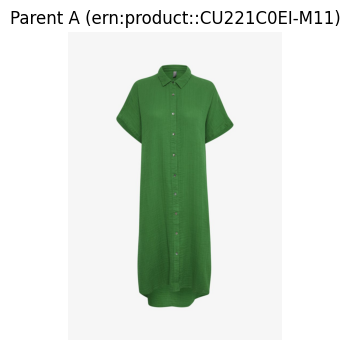

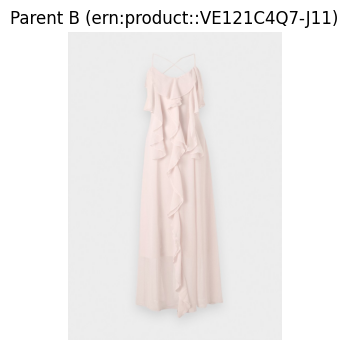

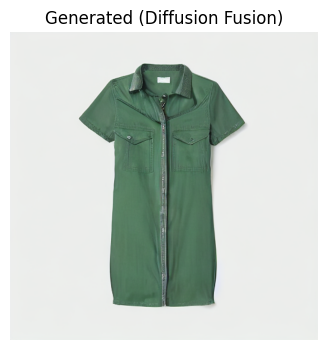

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

id_to_item = {it.item_id: it for it in items}
pA, pB = rec["parents"]
out_path = rec["output"]["image_path"]

def show(path, title):
    img = Image.open(path).convert("RGB")
    plt.figure(figsize=(4,4))
    plt.imshow(img)
    plt.axis("off")
    plt.title(title)
    plt.show()

show(id_to_item[pA].image_path, f"Parent A ({pA})")
show(id_to_item[pB].image_path, f"Parent B ({pB})")
show(out_path, "Generated (Diffusion Fusion)")


In [ ]:
# Install deps (once per runtime)
#!pip -q install diffusers transformers accelerate safetensors torch torchvision pillow

from fusion_engine import load_items, build_or_load_embeddings, generate_one
from diffusion_generator import DiffusionConfig

items = load_items("/content/items.json")
embeddings = build_or_load_embeddings(items, cache_path="/content/embeddings.pt")

cfg = DiffusionConfig(
    model_id="runwayml/stable-diffusion-v1-5",
    inpaint_model_id="runwayml/stable-diffusion-inpainting",
    prompt="fashion garment, studio lighting, product photo, clean background",
    steps=30,
    strength=0.75,          # base strength; mutation/crossover will automatically push to ~0.8+
    guidance_scale=7.5,
    seed=42
)

# ✅ Pick ONE mode:
# mode = "diffusion"         # conservative latent fusion
# mode = "inpaint_mutation"  # strong novelty (edits one parent region)
mode = "inpaint_crossover"   # best hybrid (fusion -> inpaint region with B cues)

rec = generate_one(
    items=items,
    embeddings=embeddings,
    fusion_runs_path="/content/fusion_runs.json",
    category="dress",
    styleA="formal",
    styleB="casual",
    alpha=0.5,
    mode=mode,
    output_dir="/content/outputs",
    diffusion_cfg=cfg
)

print("Mode:", mode)
print("Parents:", rec["parents"])
print("Output image:", rec["output"]["image_path"])
rec["output"]


/usr/local/lib/python3.12/dist-packages/torch/amp/autocast_mode.py:270: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn(
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Keyword 

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


  0%|          | 0/22 [00:00<?, ?it/s]

model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

... (14 outputs left out)

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


  0%|          | 0/24 [00:00<?, ?it/s]

Mode: inpaint_crossover
Parents: ['ern:product::KA321C1BF-Q11', 'ern:product::VEY29F00W-Q11']
Output image: /content/outputs/run_1767463513_4553_stage2_cross_center.png


{'image_path': '/content/outputs/run_1767463513_4553_stage2_cross_center.png',
 'stage': 'fused_then_inpaint_crossover',
 'region': 'center',
 'intermediate_fused': '/content/outputs/run_1767463513_4553_stage1_fused.png'}

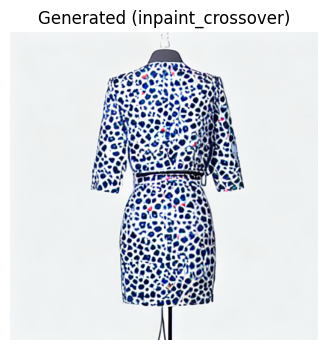

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(rec["output"]["image_path"]).convert("RGB")
plt.figure(figsize=(4,4))
plt.imshow(img)
plt.axis("off")
plt.title(f"Generated ({mode})")
plt.show()


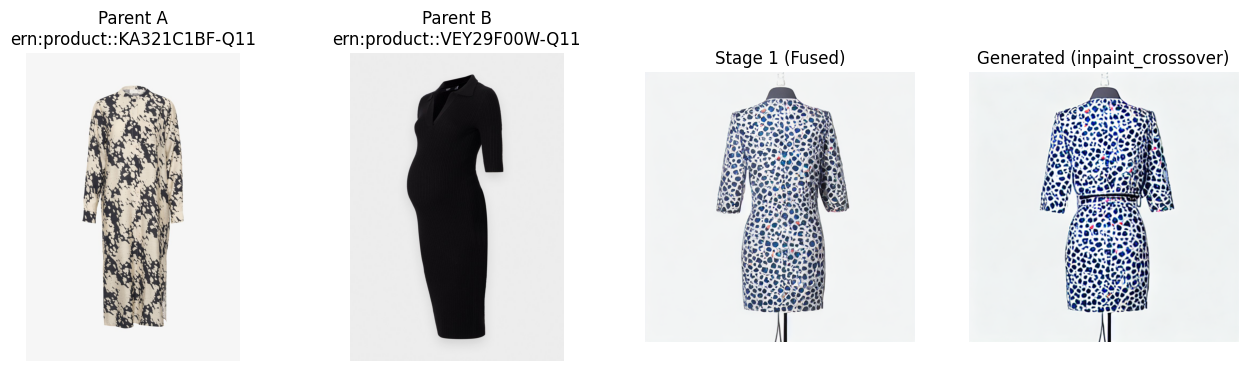

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

# Build id->item lookup
id2item = {it.item_id: it for it in items}

pA, pB = rec["parents"]
imgA = Image.open(id2item[pA].image_path).convert("RGB")
imgB = Image.open(id2item[pB].image_path).convert("RGB")
gen  = Image.open(rec["output"]["image_path"]).convert("RGB")

# If crossover mode, you may also have an intermediate fused image
mid_path = rec["output"].get("intermediate_fused", None)
mid = Image.open(mid_path).convert("RGB") if mid_path and os.path.exists(mid_path) else None

ncols = 4 if mid is not None else 3
plt.figure(figsize=(4*ncols, 4))

plt.subplot(1, ncols, 1)
plt.imshow(imgA); plt.axis("off"); plt.title(f"Parent A\n{pA}")

plt.subplot(1, ncols, 2)
plt.imshow(imgB); plt.axis("off"); plt.title(f"Parent B\n{pB}")

if mid is not None:
    plt.subplot(1, ncols, 3)
    plt.imshow(mid); plt.axis("off"); plt.title("Stage 1 (Fused)")

    plt.subplot(1, ncols, 4)
    plt.imshow(gen); plt.axis("off"); plt.title("Generated (inpaint_crossover)")
else:
    plt.subplot(1, ncols, 3)
    plt.imshow(gen); plt.axis("off"); plt.title("Generated")

plt.show()


In [ ]:
from fusion_engine_new import load_items, build_or_load_embeddings, generate_one
from diffusion_generator import DiffusionConfig

items = load_items("/content/items.json")
embeddings = build_or_load_embeddings(items, cache_path="/content/embeddings.pt")

cfg = DiffusionConfig(
    model_id="runwayml/stable-diffusion-v1-5",
    inpaint_model_id="runwayml/stable-diffusion-inpainting",
    prompt="fashion garment, studio lighting, product photo, clean background",
    steps=30,
    strength=0.75,
    guidance_scale=7.5,
    seed=42
)

# ✅ This will pick Parent A from dresses, Parent B from trousers (jeans/broeken)
rec = generate_one(
    items=items,
    embeddings=embeddings,
    fusion_runs_path="/content/fusion_runs1.json",

    # category is just for logging now; keep it as "dress" or set "any"
    category="any",

    styleA="formal",
    styleB="casual",
    alpha=0.5,

    mode="inpaint_crossover",
    output_dir="/content/outputs1",
    diffusion_cfg=cfg,

    # ✅ NEW: cross-category parents
    parentA_category="dress",
    parentB_category="trousers",
    # Optional: extra safety using garment types if your items.json has them
    parentA_garment_type="one_piece",
    parentB_garment_type="bottom",
)

print("Parents:", rec["parents"])
print("Parent categories:", rec["constraints"]["parentA_category"], rec["constraints"]["parentB_category"])
print("Output:", rec["output"]["image_path"])


  0%|          | 0/22 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

Parents: ['ern:product::TAS21C0P7-G11', 'ern:product::7SA2100H6-Q11']
Parent categories: dress trousers
Output: /content/outputs1/run_1767470788_0340_stage2_cross_top.png


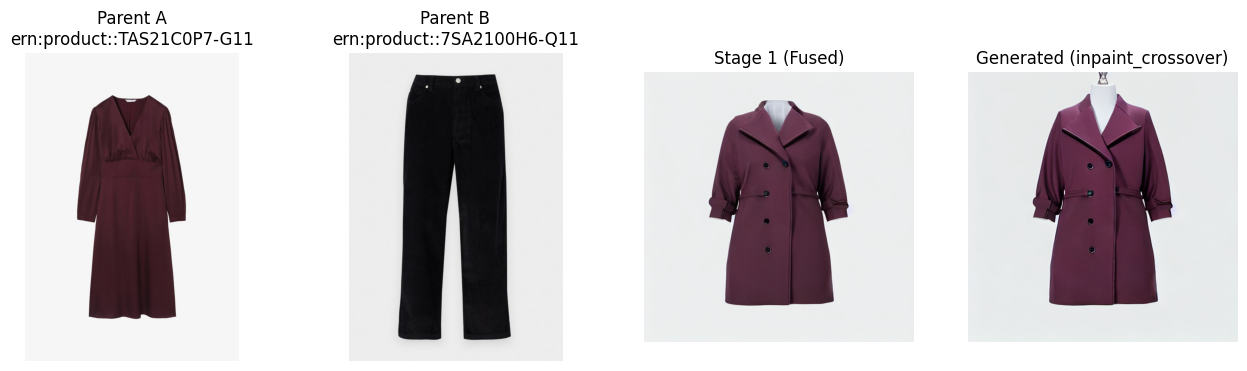

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

# Build id->item lookup
id2item = {it.item_id: it for it in items}

pA, pB = rec["parents"]
imgA = Image.open(id2item[pA].image_path).convert("RGB")
imgB = Image.open(id2item[pB].image_path).convert("RGB")
gen  = Image.open(rec["output"]["image_path"]).convert("RGB")

# If crossover mode, you may also have an intermediate fused image
mid_path = rec["output"].get("intermediate_fused", None)
mid = Image.open(mid_path).convert("RGB") if mid_path and os.path.exists(mid_path) else None

ncols = 4 if mid is not None else 3
plt.figure(figsize=(4*ncols, 4))

plt.subplot(1, ncols, 1)
plt.imshow(imgA); plt.axis("off"); plt.title(f"Parent A\n{pA}")

plt.subplot(1, ncols, 2)
plt.imshow(imgB); plt.axis("off"); plt.title(f"Parent B\n{pB}")

if mid is not None:
    plt.subplot(1, ncols, 3)
    plt.imshow(mid); plt.axis("off"); plt.title("Stage 1 (Fused)")

    plt.subplot(1, ncols, 4)
    plt.imshow(gen); plt.axis("off"); plt.title("Generated (inpaint_crossover)")
else:
    plt.subplot(1, ncols, 3)
    plt.imshow(gen); plt.axis("off"); plt.title("Generated")

plt.show()
